# Arabic legal documents: data preparation

Run locally in VS Code. Select `.venv/bin/python` as the notebook kernel and install `requirements.txt` from the terminal first. PDF rendering uses PyMuPDF and does not require Poppler.


In [1]:
import sys  # Built-in: shows which Python interpreter runs the notebook.

print(f"Python interpreter: {sys.executable}")


Python interpreter: /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/.venv/bin/python


## Install PDF-processing dependencies

Run this cell once in your selected notebook kernel. `%pip` installs into that kernel’s environment. Restart the kernel after installation, then run the remaining cells in order. Select the project’s `.venv/bin/python` to use the environment prepared for this project.


In [2]:
%pip install "PyMuPDF>=1.26,<2" "Pillow>=12.2.0,<13" "tqdm>=4.67,<5"



Note: you may need to restart the kernel to use updated packages.


## Start

PDFs are read from the project’s `data` folder.


In [3]:
import os  # Built-in: provides operating-system tools for files, folders, and environment variables.
from os.path import join  # Built-in: combines folder and file names into a path.
import random  # Built-in: supports random sampling and shuffling for later data preparation.
from tqdm import tqdm  # Displays progress bars when processing multiple documents or pages.

from glob import glob  # Built-in: finds files matching a pattern, such as "*.pdf".
from pathlib import Path  # Built-in: handles paths and checks whether files or folders exist.
import pymupdf  # Renders PDF pages directly into images without external tools.
from PIL import Image  # Pillow: opens, resizes, and saves images for VLM inputs.
from PIL import ImageEnhance  # Pillow: adjusts image contrast before OCR.

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
data_dir = str(project_dir / "data")

if not Path(data_dir).is_dir():
    raise FileNotFoundError(f"Data folder not found: {data_dir}. Open the project folder in VS Code.")
print(f"Data directory: {data_dir}")
pdf_files = glob(join(data_dir, "*.pdf"))
print(f"PDF files: {len(pdf_files)}")


Data directory: /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/data
PDF files: 4


## Hugging Face authentication (local)

This replaces Colab secrets and shell login with local `.env` loading and the Hugging Face Python API. Run the project-path cell above first. Set `HF_TOKEN` in `.env`, then run this cell to validate it and save it in the local Hugging Face authentication cache. Only the account name is printed. The token is not added to Git credentials.

This cell is needed for model access, not PDF conversion; you can skip it when preparing images only. The packages `python-dotenv` and `huggingface-hub` are installed through the project requirements (the latter is also a Transformers dependency). Gemma access may require accepting the model terms on Hugging Face.


In [4]:
from dotenv import dotenv_values  # Reads local configuration without printing credentials.
from huggingface_hub import HfApi, login  # Authenticates with Hugging Face through its Python API.

# Read the project-specific token directly from the ignored .env file.
env_path = project_dir / ".env"
hf_token = (dotenv_values(env_path).get("HF_TOKEN") or "").strip()

if not hf_token:
    raise RuntimeError("Set HF_TOKEN in the project's .env file before running authentication.")

try:
    # Validate the token before saving it in Hugging Face's local authentication cache.
    hf_account = HfApi().whoami(token=hf_token)
    login(token=hf_token, add_to_git_credential=False)
except Exception:
    raise RuntimeError("Hugging Face login failed. Check the token and network connection.") from None

print(f"Hugging Face authentication successful: {hf_account['name']}")


/Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face authentication successful: jaberimohamed


## Document Analysis & Extraction Prompt

`document_extraction_prompt` defines structured JSON extraction: metadata, dates, references, content, and visual elements. Run this cell before generation, which selects `prompt = document_extraction_prompt`. Defining the prompt does not run inference.

The field template describes expected values; it does not automatically validate JSON. The complete task may exceed the current 1,024-token limit, especially with `full_text`. Check truncation and source fidelity; use targeted tasks when necessary.

`image_to_base64_data_uri` accepts local paths and identifies the MIME type from the image format. It encodes bytes without sending a network request. Local Gemma uses the RGB Pillow image directly. Do not print the complete data URI.


In [5]:
import base64  # Built-in: encodes image bytes for an optional API data URI.
from pathlib import Path
from PIL import Image


def image_to_base64_data_uri(image_path):
    """Encode a local image as a data URI; this function does not send it anywhere."""
    image_path = Path(image_path)
    # Read MIME type from the actual file format, not just its extension.
    with Image.open(image_path) as image:
        mime_type = Image.MIME.get(image.format)
    if mime_type is None:
        raise ValueError("Unsupported image format for a data URI.")
    encoded = base64.b64encode(image_path.read_bytes()).decode("ascii")
    return f"data:{mime_type};base64,{encoded}"


# Separate from the short OCR transcription prompt used by the current baseline.
document_extraction_prompt = """
# Document Analysis & Extraction Prompt

Analyze only the supplied page image and return a valid JSON object with the structure below.
The template describes field types and allowed enum values; these descriptions are NOT output values.
Choose enum values only when supported by visible evidence. Use null for absent, unreadable,
or ambiguous scalar values, including booleans and enums. Use [] for collections with no
observed elements. Do not claim a collection is complete when the image is unreadable.

## Output field template
{
  "document_classification": {
    "type": "enum: official_letter | decree | regulation | statistical_report | table_of_contents | administrative_decision | legal_amendment | memo | certificate | form | invoice | contract | court_ruling | minutes | circular | announcement | report | other",
    "subtype": "string or null",
    "category": "enum: legal | administrative | financial | statistical | correspondence | technical | hr | other",
    "primary_language": "enum: arabic | english | french | mixed | other",
    "secondary_languages": [
      "array of language codes if multilingual"
    ]
  },
  "source": {
    "issuing_authority": "string: full organization name in ORIGINAL SCRIPT",
    "department": "string or null: specific division/unit in ORIGINAL SCRIPT",
    "location": "string or null: city/region",
    "document_number": "string or null: official reference number EXACTLY as shown",
    "related_references": [
      "array: all other document numbers mentioned anywhere in document"
    ],
    "dates": {
      "primary_date": {
        "date_text": "string or null: main date exactly as visible; null if ambiguous",
        "calendar_type": "enum: hijri | gregorian | unknown",
        "date_type": "enum: issue_date | effective_date | received_date | other",
        "indicators": "string or null: visible calendar markers",
        "location_in_document": "enum: header | body | footer | stamp | other"
      },
      "additional_dates": [
        {
          "date_text": "string: EXACTLY as written",
          "calendar_type": "enum: hijri | gregorian | unknown",
          "date_type": "enum: reference_date | deadline | expiry_date | effective_date | other",
          "context": "string: brief context of where/why this date appears",
          "indicators": "string or null"
        }
      ]
    }
  },
  "physical_properties": {
    "page_number": "string: e.g., '7', '7/254', 'single', 'unknown'",
    "total_pages": "integer or null",
    "image_type": "enum: digital | scanned | photographed | mixed | unknown",
    "quality": "enum: high | medium | low | illegible",
    "color_mode": "enum: color | grayscale | black_white | mixed",
    "has_watermark": "boolean or null: null if not determinable",
    "watermark_description": "string or null",
    "has_security_pattern": "boolean or null: null if not determinable",
    "security_pattern_description": "string or null",
    "orientation": "enum: portrait | landscape"
  },
  "official_marks": {
    "seals": [
      {
        "organization": "string: in ORIGINAL SCRIPT",
        "position": "enum: header | footer | center | top_right | top_left | bottom_right | bottom_left | margin | overlapping_text | other",
        "description": "string: detailed visual description",
        "is_digital": "boolean or null: do not infer digital origin from appearance alone",
        "shape": "enum: circular | oval | rectangular | square | irregular | other"
      }
    ],
    "stamps": [
      {
        "type": "enum: approval | received | confidential | urgent | date_stamp | routing | registry | copy | original | other",
        "text_content": "string: ALL text on stamp in ORIGINAL SCRIPT",
        "color": "enum: red | blue | black | green | purple | brown | other",
        "position": "enum: header | footer | center | top_right | top_left | bottom_right | bottom_left | margin | overlapping_text | other",
        "is_digital": "boolean or null: do not infer digital origin from appearance alone",
        "shape": "enum: circular | rectangular | square | oval | irregular"
      }
    ],
    "barcodes_qr": [
      {
        "type": "enum: barcode | qr_code | data_matrix | other",
        "position": "string",
        "readable_data": "string or null"
      }
    ]
  },
  "signatures_authorization": {
    "signatories": [
      {
        "name": "string: EXACTLY as written in ORIGINAL SCRIPT (Arabic/English/etc)",
        "name_transliteration": "string or null: only if BOTH scripts appear in document",
        "title": "string: official position in ORIGINAL SCRIPT",
        "signature_type": "enum: handwritten | digital | stamp | printed_name | not_present",
        "position": "enum: bottom_left | bottom_right | bottom_center | top_right | top_left | middle_right | middle_left | end_of_document | other",
        "role": "enum: primary_signatory | co_signatory | witness | approver | preparer | reviewer | other"
      }
    ],
    "approval_chain": [
      {
        "step": "integer: order in chain (1, 2, 3...)",
        "role": "enum: prepared_by | reviewed_by | approved_by | authorized_by | noted_by | verified_by | other",
        "name": "string or null: in ORIGINAL SCRIPT",
        "title": "string or null: in ORIGINAL SCRIPT",
        "date": "string or null"
      }
    ]
  },
  "routing_distribution": {
    "addressed_to": [
      {
        "type": "enum: person | department | organization | position | general",
        "name": "string: in ORIGINAL SCRIPT",
        "honorific": "string or null: titles like 'فضيلة', 'سعادة', 'معالي'"
      }
    ],
    "carbon_copy": [
      {
        "type": "enum: person | department | organization | position",
        "name": "string: in ORIGINAL SCRIPT"
      }
    ],
    "forwarded_to": [
      {
        "type": "enum: person | department | organization | position",
        "name": "string: in ORIGINAL SCRIPT",
        "date": "string or null"
      }
    ],
    "file_reference": "string or null: internal filing/tracking code",
    "classification": "string or null: security/filing classification in ORIGINAL SCRIPT"
  },
  "content": {
    "subject": "string: document subject/title in ORIGINAL SCRIPT",
    "subject_translation": "string or null: only if explicitly needed",
    "keywords": [
      "array: 5-10 keywords in ORIGINAL SCRIPT"
    ],
    "full_text": "string: complete text extraction with line breaks, in ORIGINAL SCRIPT",
    "has_tables": "boolean or null: null if not evaluated or uncertain",
    "tables": [
      {
        "title": "string or null: in ORIGINAL SCRIPT",
        "headers": [
          "array: column headers in ORIGINAL SCRIPT"
        ],
        "rows": [
          [
            "array of cell values per row in ORIGINAL SCRIPT"
          ]
        ],
        "notes": "string or null"
      }
    ],
    "has_lists": "boolean or null: null if not evaluated or uncertain",
    "lists": [
      {
        "type": "enum: numbered | bulleted | lettered | arabic_numbered | hierarchical",
        "items": [
          "array: items in ORIGINAL SCRIPT with hierarchy preserved"
        ]
      }
    ],
    "has_charts": "boolean or null: null if not evaluated or uncertain",
    "charts": [
      {
        "type": "enum: bar | line | pie | area | scatter | table | mixed | other",
        "title": "string or null: chart title in ORIGINAL SCRIPT",
        "description": "string: brief description of what chart displays",
        "data": [
          {
            "label": "string: category/bar/data point label in ORIGINAL SCRIPT",
            "value": "string or null: copy the explicitly printed value; do not estimate from axes or geometry",
            "position": "integer: order/sequence (1, 2, 3...)"
          }
        ],
        "axis_info": {
          "x_axis_label": "string or null: in ORIGINAL SCRIPT",
          "y_axis_label": "string or null: in ORIGINAL SCRIPT",
          "x_axis_type": "enum: categorical | numerical | date | other",
          "y_axis_type": "enum: categorical | numerical | percentage | other"
        },
        "notes": "string or null: any footnotes or additional chart info"
      }
    ],
    "legal_articles": [
      {
        "article_number": "string: in ORIGINAL SCRIPT e.g., 'المادة الأولى', 'Article 1'",
        "article_title": "string or null: in ORIGINAL SCRIPT",
        "content": "string: full article text in ORIGINAL SCRIPT"
      }
    ],
    "financial_data": [
      {
        "description": "string: in ORIGINAL SCRIPT",
        "amount": "string: numerical value EXACTLY as shown",
        "currency": "string: SAR, USD, etc. or in ORIGINAL SCRIPT"
      }
    ]
  },
  "structural_elements": {
    "header": {
      "present": "boolean",
      "content": "string or null: ALL header text in ORIGINAL SCRIPT",
      "has_logo": "boolean",
      "logo_description": "string or null",
      "reference_numbers": [
        "array: any reference numbers in header"
      ]
    },
    "footer": {
      "present": "boolean",
      "content": "string or null: ALL footer text in ORIGINAL SCRIPT",
      "has_page_number": "boolean",
      "page_info": "string or null: page numbering format"
    },
    "letterhead": {
      "present": "boolean",
      "organization_name": "string or null: in ORIGINAL SCRIPT",
      "organization_name_secondary": "string or null: if in another language",
      "emblem_description": "string or null",
      "contact_info": "string or null: addresses, phones, emails, websites"
    },
    "margins_notes": {
      "has_margin_notes": "boolean",
      "margin_content": "string or null: any handwritten or printed margin notes in ORIGINAL SCRIPT"
    }
  },
  "attachments_references": {
    "attachments_mentioned": [
      {
        "description": "string: in ORIGINAL SCRIPT",
        "count": "integer or null",
        "reference_number": "string or null"
      }
    ],
    "referenced_documents": [
      {
        "type": "enum: law | regulation | decree | previous_decision | letter | circular | report | contract | minutes | other",
        "reference": "string: document identifier in ORIGINAL SCRIPT",
        "date": "string or null: if date is mentioned for this reference"
      }
    ]
  },
  "condition_notes": {
    "completeness": "enum: complete | partial | missing_pages | fragment | unknown",
    "legibility_issues": [
      "array: describe sections with poor legibility"
    ],
    "physical_damage": "enum: none | minor | moderate | severe | not_applicable",
    "damage_description": "string or null",
    "handwritten_annotations": {
      "present": "boolean",
      "description": "string or null: describe notes, highlights, corrections"
    },
    "special_observations": "string or null"
  },
  "confidence_quality": {
    "overall_confidence": "enum: high | medium | low",
    "uncertain_elements": [
      "array: list specific elements with low confidence"
    ],
    "requires_manual_review": "boolean",
    "review_reasons": [
      "array: specific areas needing verification"
    ]
  }
}

## Critical extraction rules
- Preserve all source text in its original script, including Arabic names, titles, digits,
  separators, parentheses, punctuation and diacritics. Never transliterate or translate.
- Keep subject_translation null unless translation is explicitly requested separately.
- Do not correct, summarize, invent, or complete text. Use [غير مقروء] for unreadable
  spans in full_text and null for uncertain extracted fields.
- Separate THIS document's number, other cited references, and internal file references.
- Separate the document's primary date from additional dates. A header position alone
  is not enough to prove a date's role; retain the original date without conversion.
- Copy names and titles as printed. Fill name_transliteration only if that alternate
  spelling is itself visible in the supplied document.
- Record observable stamps and seals separately from letterhead logos. Do not certify
  authenticity, digital origin, signatory identity, or approval order from appearance alone.
- The image may have been resized or converted to grayscale: report the supplied image's
  appearance, not an invented original stamp color or original capture history.
- Leave barcode/QR readable_data null unless an independently verified decoded value
  is supplied. Do not guess a machine-readable payload from pixels.
- Preserve table column order and empty cells. Do not compute or infer missing amounts.
- Copy only explicitly printed chart values. Axis ticks or bar heights are not exact
  data-point labels. Leave uncertain values null and record the uncertainty.
- Extract legal articles and financial amounts exactly, without external legal interpretation,
  currency conversion, or normalization of numbers.
- Include visible header, body, footer, stamp text, signatures' printed text and chart labels
  in full_text, preserving reading order and line breaks. Do not omit source text simply
  because it also appears in a structured field.
- Keywords must be grounded in the page; do not invent items to reach a count of 5-10.
- Analyze only supplied pages. Do not assert that the full PDF is complete from one image.
- Confidence is a qualitative model report, not a calibrated guarantee. Mark ambiguous
  fields in uncertain_elements and require manual review where appropriate.
- Return actual values, not template descriptions. Return ONLY JSON: no code fences,
  introductions, comments, ellipses, or additional explanation.
""".strip()



## Pdf to Images

In [6]:
def preprocess_image(image, max_width=600):
    """
    Preprocess image to reduce size and prepare for OCR.

    Args:
        image: PIL Image object
        max_width: Maximum width in pixels (height auto-calculated to maintain ratio)

    Steps:
    1. Convert to grayscale (reduces size and improves OCR)
    2. Resize to reasonable width while maintaining aspect ratio
    3. Increase contrast
    """

    # Convert to grayscale
    gray_image = image.convert('L')

    # Resize if image is too large
    if gray_image.width > max_width:
        # Calculate new height to maintain aspect ratio
        ratio = max_width / gray_image.width
        new_height = int(gray_image.height * ratio)
        gray_image = gray_image.resize((max_width, new_height), Image.LANCZOS)

    enhancer = ImageEnhance.Contrast(gray_image)
    enhanced_image = enhancer.enhance(1.5)

    return enhanced_image


In [7]:
def convert_pdf_to_images(pdf_path, output_base_dir, max_width=600):
    """
    Render PDF pages with PyMuPDF, preprocess them, and save JPEG images.

    Args:
        pdf_path: Path to the PDF file.
        output_base_dir: Base directory to save images.
        max_width: Maximum output width in pixels (default: 600).
    """
    pdf_name = os.path.splitext(os.path.basename(pdf_path))[0]
    output_dir = join(output_base_dir, pdf_name)
    os.makedirs(output_dir, exist_ok=True)
    print(f"Converting {pdf_name}.pdf...")
    generated_paths = []

    # Render one page at a time to avoid loading the entire PDF into memory.
    with pymupdf.open(pdf_path) as document:
        for page_num, page in enumerate(document, start=1):
            # Render at 200 DPI in RGB; no external Poppler installation is needed.
            pixmap = page.get_pixmap(dpi=200, colorspace=pymupdf.csRGB, alpha=False)
            image = Image.frombytes("RGB", (pixmap.width, pixmap.height), pixmap.samples)
            processed_image = preprocess_image(image, max_width)

            output_path = join(output_dir, f"page_{page_num:03d}.jpg")
            processed_image.save(output_path, "JPEG", quality=85, optimize=True)
            image.close()
            processed_image.close()
            print(f"  Saved page {page_num} -> {output_path}")
            generated_paths.append(output_path)

    return generated_paths


### Test PDF conversion

This cell tests the PDF-to-image pipeline on `reconciliation_center_regulations.pdf` in the local `data/` folder. It checks that the PDF exists, then calls `convert_pdf_to_images()`.

Each page is rendered with PyMuPDF at 200 DPI, converted to grayscale, resized to a maximum width of 600 pixels while preserving its aspect ratio, and given increased contrast. The processed pages are saved as JPEG files named `page_001.jpg`, `page_002.jpg`, and so on, under `outputs/images/reconciliation_center_regulations/`. The cell returns their paths in `generated_paths` and prints the number of images created.

This checks image preparation; it does not extract text or train a model. You can change `sample_pdf_path` to test another PDF and adjust `max_width` to retain more detail. Running it again overwrites images with the same filenames.


In [8]:
# Select an existing PDF from the local data folder.
sample_pdf_path = Path(data_dir) / "reconciliation_center_regulations.pdf"

# Store generated images inside the project instead of Colab's /content folder.
output_base_dir = project_dir / "outputs" / "images"

if not sample_pdf_path.is_file():
    raise FileNotFoundError(f"Sample PDF not found: {sample_pdf_path}")

generated_paths = convert_pdf_to_images(
    pdf_path=str(sample_pdf_path),
    output_base_dir=str(output_base_dir),
    max_width=600,  # A 200px page is usually too small to read Arabic text clearly.
)

print(f"Generated {len(generated_paths)} images in {output_base_dir / sample_pdf_path.stem}")


Converting reconciliation_center_regulations.pdf...
  Saved page 1 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/reconciliation_center_regulations/page_001.jpg
  Saved page 2 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/reconciliation_center_regulations/page_002.jpg
  Saved page 3 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/reconciliation_center_regulations/page_003.jpg
  Saved page 4 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/reconciliation_center_regulations/page_004.jpg
Generated 4 images in /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/reconciliation_center_regulations


### List and convert all PDFs

This cell lists all PDFs in the local `data/` folder and converts every document into preprocessed page images, showing a progress bar. Images are saved under `outputs/images/<pdf_name>/` at a maximum width of 600 pixels. `all_generated_paths` stores the output paths for each document. Run the imports and function definitions above first. Running this again overwrites images with the same filenames.


In [9]:
# Find and list every PDF in the project's data folder.
pdf_files = sorted(glob(join(data_dir, "*.pdf")))
output_dir = project_dir / "outputs" / "images"
max_width = 600

if not pdf_files:
    raise FileNotFoundError(f"No PDF files found in {data_dir}")

print(f"Found {len(pdf_files)} PDFs:")
for pdf_file in pdf_files:
    print(f"  - {Path(pdf_file).name}")

# Convert all PDFs, keeping each document's pages in its own folder.
all_generated_paths = {}
for pdf_file in tqdm(pdf_files, desc="Converting PDFs", unit="pdf"):
    all_generated_paths[Path(pdf_file).name] = convert_pdf_to_images(
        pdf_path=pdf_file,
        output_base_dir=str(output_dir),
        max_width=max_width,
    )

image_count = sum(len(paths) for paths in all_generated_paths.values())
print(f"Generated {image_count} page images from {len(pdf_files)} PDFs.")


Found 4 PDFs:
  - appeal_procedures_implementing_regulations.pdf
  - judicial_documents_regulations.pdf
  - reconciliation_center_regulations.pdf
  - state_funded_lawyer_fees.pdf


Converting PDFs:   0%|          | 0/4 [00:00<?, ?pdf/s]

Converting appeal_procedures_implementing_regulations.pdf...
  Saved page 1 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/appeal_procedures_implementing_regulations/page_001.jpg
  Saved page 2 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/appeal_procedures_implementing_regulations/page_002.jpg
  Saved page 3 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/appeal_procedures_implementing_regulations/page_003.jpg
  Saved page 4 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/appeal_procedures_implementing_regulations/page_004.jpg
  Saved page 5 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/appeal_procedures_implementing_regulations/page_005.jpg
  Saved page 6 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/appeal_procedures_implementing_regulations/page_006.jpg
  Saved page 7 -> /Us

Converting PDFs:  25%|██▌       | 1/4 [00:01<00:03,  1.22s/pdf]

  Saved page 17 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/appeal_procedures_implementing_regulations/page_017.jpg
  Saved page 18 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/appeal_procedures_implementing_regulations/page_018.jpg
  Saved page 19 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/appeal_procedures_implementing_regulations/page_019.jpg
  Saved page 20 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/appeal_procedures_implementing_regulations/page_020.jpg
Converting judicial_documents_regulations.pdf...
  Saved page 1 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/judicial_documents_regulations/page_001.jpg
  Saved page 2 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/judicial_documents_regulations/page_002.jpg
  Saved page 3 -> /Users/ET35771/Documents/AI/project

Converting PDFs:  50%|█████     | 2/4 [00:01<00:01,  1.32pdf/s]

  Saved page 5 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/judicial_documents_regulations/page_005.jpg
  Saved page 6 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/judicial_documents_regulations/page_006.jpg
Converting reconciliation_center_regulations.pdf...
  Saved page 1 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/reconciliation_center_regulations/page_001.jpg
  Saved page 2 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/reconciliation_center_regulations/page_002.jpg


Converting PDFs:  75%|███████▌  | 3/4 [00:02<00:00,  1.27pdf/s]

  Saved page 3 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/reconciliation_center_regulations/page_003.jpg
  Saved page 4 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/reconciliation_center_regulations/page_004.jpg
Converting state_funded_lawyer_fees.pdf...
  Saved page 1 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/state_funded_lawyer_fees/page_001.jpg
  Saved page 2 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/state_funded_lawyer_fees/page_002.jpg
  Saved page 3 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/state_funded_lawyer_fees/page_003.jpg


Converting PDFs: 100%|██████████| 4/4 [00:02<00:00,  1.37pdf/s]

  Saved page 4 -> /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/images/state_funded_lawyer_fees/page_004.jpg
Generated 34 page images from 4 PDFs.


## Evaluate Base Model

Prepare the instruction-tuned checkpoint `google/gemma-3-4b-it` and a local page for evaluation before finetuning.

This cell imports model and processor classes, checks the image, converts it to RGB, and detects CUDA, Apple MPS, or CPU. It does not download weights or generate text. Run project-path setup and single-PDF conversion first.


### Install model dependencies

Run this installation cell in the active notebook kernel if Transformers or PyTorch is missing. Restart the kernel afterward and rerun the imports, project-path setup, and image preparation cells. `%pip` targets the notebook environment rather than another terminal Python installation. This installs libraries, not model weights.


In [10]:
%pip install "transformers>=4.57,<5" "torch>=2.5,<3" "accelerate>=1,<2" "Pillow>=12.2.0,<13"


Note: you may need to restart the kernel to use updated packages.


In [11]:
from transformers import AutoProcessor, Gemma3ForConditionalGeneration  # Prepares model inputs and provides Gemma 3's vision-language model class.
from PIL import Image  # Opens the local page image for future model input.
import torch  # Provides tensors and detects available computation hardware.

# Use the instruction-tuned checkpoint selected for this project.
model_id = "google/gemma-3-4b-it"

# Select a page produced by the PDF conversion section above.
sample_image_path = project_dir / "outputs" / "images" / "reconciliation_center_regulations" / "page_001.jpg"
if not sample_image_path.is_file():
    raise FileNotFoundError("Run the single-PDF conversion cell first to create the sample image.")

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"  # Apple Silicon GPU.
else:
    device = "cpu"

with Image.open(sample_image_path) as image:
    sample_image = image.convert("RGB")

print(f"Model checkpoint: {model_id}")
print(f"Available device: {device}")
print(f"Sample image: {sample_image_path.name}, size: {sample_image.size}")


Model checkpoint: google/gemma-3-4b-it
Available device: mps
Sample image: page_001.jpg, size: (600, 844)


### Preview the sample page

Display the selected JPEG inline to inspect text legibility before model inference. Run the base-model setup cell first; it defines and validates `sample_image_path`. This preview does not perform OCR.


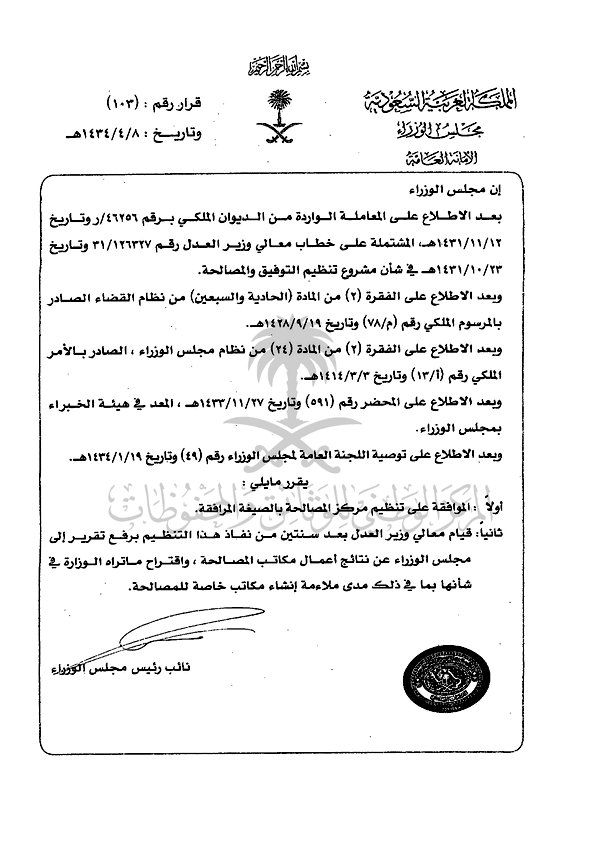

In [12]:
from IPython.display import display, Image as IPImage  # Displays a local image inline without conflicting with Pillow's Image.

# Run the base-model setup cell first to define sample_image_path.
display(IPImage(filename=str(sample_image_path)))


### Load Gemma and its processor

Run Hugging Face authentication and the model setup cells first. This cell downloads `google/gemma-3-4b-it` weights on first use and caches them locally, then loads the model in evaluation mode and its matching processor. Access requires approval of the Gemma terms for your Hugging Face account.

`dtype="auto"` uses the checkpoint precision; it does not quantize the model. `device_map="auto"` uses Accelerate to determine device placement, which is printed after loading. It does not guarantee that every layer runs on the Apple GPU. Model weights alone require several GB, and inference needs additional memory. Loading may fail if RAM or device memory is insufficient. `.eval()` does not disable gradients; generation will use `torch.inference_mode()` in a later cell. This cell does not generate text.


In [13]:
# Download/cache the weights and let Accelerate choose their placement.
print(f"Loading {model_id}: downloading/loading weights may take time...", flush=True)
model = Gemma3ForConditionalGeneration.from_pretrained(
    model_id,
    dtype="auto",       # Uses the checkpoint's floating-point precision; this is not quantization.
    device_map="auto",  # Placement depends on available hardware and memory, not just the device variable.
).eval()  # Evaluation mode disables training behavior such as dropout.

# Load the image processor, tokenizer, and chat template for this checkpoint.
print("Loading processor...", flush=True)
processor = AutoProcessor.from_pretrained(model_id)

print(f"Model loaded: {model_id}")
print(f"Model dtype: {model.dtype}")
print(f"Device placement: {getattr(model, 'hf_device_map', None)}")


Loading google/gemma-3-4b-it: downloading/loading weights may take time...


Loading checkpoint shards: 100%|██████████| 2/2 [00:23<00:00, 11.74s/it]


Loading processor...


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Model loaded: google/gemma-3-4b-it
Model dtype: torch.bfloat16
Device placement: {'': 'mps'}


### Generate a baseline transcription

Run the model-loading and image-preparation cells first. The processor packages the RGB image and a source-faithful transcription prompt into Gemma’s chat format. Greedy generation runs without gradients, and only newly generated tokens are decoded. The cell prints transcription, generation duration, and output token count, with a warning when the 1,024-token budget is reached.

Check the output against the source image: a prompt and deterministic decoding cannot eliminate hallucination. `[غير مقروء]` is the requested marker for unreadable text. This is a qualitative baseline, not a scored accuracy evaluation. The timing covers generation only, not model loading or input processing.


In [14]:
import time  # Measures generation time for this baseline run.
from transformers import TextStreamer  # Prints decoded text progressively during generation.

print(f"Preparing image inputs; model device: {model.device}", flush=True)
print(f"Device placement: {getattr(model, 'hf_device_map', None)}", flush=True)

# prompt = """
# Act as an OCR Model. Extract the exact details of the image into a markdown format.
#
# ## Output:
# ```markdown
# """.strip()

# Use the structured extraction prompt defined above.
prompt = document_extraction_prompt

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": sample_image},  # RGB Pillow image prepared above.
            {"type": "text", "text": prompt},
        ],
    }
]

inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device)

# Match image tensors to the vision encoder's precision without changing token IDs.
if "pixel_values" in inputs:
    inputs["pixel_values"] = inputs["pixel_values"].to(dtype=model.dtype)

input_len = inputs["input_ids"].shape[-1]
max_new_tokens = 1024  # For a short diagnostic run, try 128; this will not transcribe a dense page fully.

streamer = TextStreamer(processor.tokenizer, skip_prompt=True, skip_special_tokens=True)
print(f"Inputs ready: {input_len} prompt tokens; output limit: {max_new_tokens}", flush=True)

# Synchronize GPU work so the recorded duration includes completed generation.
def synchronize_generation_device():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elif model.device.type == "mps":
        torch.mps.synchronize()

synchronize_generation_device()
print("Generating: text will appear progressively. The first output may take time.", flush=True)
started_at = time.perf_counter()
with torch.inference_mode():
    output_ids = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,  # Greedy decoding; this does not guarantee transcription fidelity.
        streamer=streamer,
    )
synchronize_generation_device()
generation_seconds = time.perf_counter() - started_at

# Decode only generated tokens, excluding the input prompt.
generation = output_ids[0, input_len:]
decoded = processor.decode(generation, skip_special_tokens=True)
# Text was already displayed by the streamer; retain decoded for later use.
print(f"\nGeneration time: {generation_seconds:.2f}s; output tokens: {generation.numel()}")
if generation.numel() >= max_new_tokens:
    print("Warning: output reached max_new_tokens. Check whether the transcription is incomplete.")


Preparing image inputs; model device: mps:0
Device placement: {'': 'mps'}
Inputs ready: 3781 prompt tokens; output limit: 1024
Generating: text will appear progressively. The first output may take time.


The following generation flags are not valid and may be ignored: ['top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


```json
{
  "document_classification": {
    "type": "regulation",
    "subtype": null,
    "category": "legal",
    "primary_language": "arabic",
    "secondary_languages": []
  },
  "source": {
    "issuing_authority": "مجلس الوزراء",
    "department": null,
    "location": null,
    "document_number": "قرار رقم: (١٠٢)",
    "related_references": [],
    "dates": {
      "primary_date": {
        "date_text": "٨ / ٤ / ١٤٣٤ هـ",
        "calendar_type": "hijri",
        "date_type": "issue_date",
        "indicators": null,
        "location_in_document": "header"
      },
      "additional_dates": []
    }
  },
  "physical_properties": {
    "page_number": "١",
    "total_pages": null,
    "image_type": "scanned",
    "quality": "medium",
    "color_mode": "black_white",
    "has_watermark": null,
    "watermark_description": null,
    "has_security_pattern": null,
    "security_pattern_description": null,
    "orientation": "portrait"
  },
  "official_marks": {
    "seals": [],
    

## OpenRouter setup (optional cloud inference)

Install the requested LiteLLM version in the active notebook kernel using `%pip`, then restart the kernel if needed. Run project-path setup before the configuration cell. It reads `OPENROUTER_API_KEY` from `.env`, with support for your existing `open_router_API_KEY` name, without displaying the value. `OPENROUTER_MODEL` is an optional exact model ID to configure later.

This setup makes no API request and does not validate the key remotely. Cloud inference sends selected page images and prompts to OpenRouter and the routed provider and may incur charges. It is an optional comparison path; the local Gemma workflow remains available.


### Why use OpenRouter?

OpenRouter provides access to hosted models through a common LiteLLM interface, allowing comparison with local **Gemma 3** without downloading the hosted models' weights or owning the hardware required to run them.

Planned uses are comparing Arabic transcription and structured extraction on the same pages, producing candidate annotations for Gemma finetuning, and measuring model quality, latency, and cost with consistent prompts. Candidate annotations must be checked against the source scans before training.

The goal remains a **local model on a limited budget**. Hosted outputs can hallucinate and are not automatic ground truth. API calls may consume paid credits and transmit images and prompts to OpenRouter and the routed provider. Start with a small sample and check model pricing before scaling. Setup does not send a request; the separate Gemini evaluation cell performs the optional call when executed.


In [15]:
%pip install litellm==1.73.6


Note: you may need to restart the kernel to use updated packages.


In [16]:
from dotenv import dotenv_values  # Reads the ignored local .env configuration.
import litellm  # Unified client for model providers, including OpenRouter.

openrouter_config = dotenv_values(project_dir / ".env")
# Prefer the standard name; support the key name already present in your .env.
openrouter_token = (
    openrouter_config.get("OPENROUTER_API_KEY")
    or openrouter_config.get("open_router_API_KEY")
    or ""
).strip()
if not openrouter_token:
    raise RuntimeError("Set OPENROUTER_API_KEY in the project's .env file.")

# Select an exact vision-capable OpenRouter model before making an API request.
openrouter_model_id = (openrouter_config.get("OPENROUTER_MODEL") or "").strip()
print("OpenRouter key loaded locally (not displayed).")
print("No request sent. Select a vision-capable model before inference.")


OpenRouter key loaded locally (not displayed).
No request sent. Select a vision-capable model before inference.


### Configure the OpenRouter endpoint

Run the key-loading cell first. It reads the OpenRouter token from the ignored local `.env` file into `openrouter_token`.

The next cell sets `OPENAI_API_KEY` to that OpenRouter token and `OPENAI_BASE_URL` to `https://openrouter.ai/api/v1`. These are OpenAI-compatible client settings: the endpoint determines where requests go. An OpenAI-issued key is not required.

LiteLLM calls use `model="openai/google/gemini-3-flash-preview"` and read these settings automatically. The `openai/` prefix selects the client protocol; Gemini is the model served through OpenRouter. The cell changes this kernel's environment variables, including any previous values, but does not modify `.env`. Other OpenAI-compatible calls in this kernel will also use these settings.

**Output:** public endpoint and configuration confirmation, without displaying the token. Setup sends no request. Running evaluation or extraction sends images and prompts externally, consumes OpenRouter credits, and can fail with HTTP 402 when billing limits apply.


In [17]:
import os  # Configures the API client in this notebook kernel.

# The value is an OpenRouter token, even though the client variable says OPENAI.
os.environ["OPENAI_API_KEY"] = openrouter_token
# Send OpenAI-compatible requests to OpenRouter, not to OpenAI's endpoint.
os.environ["OPENAI_BASE_URL"] = "https://openrouter.ai/api/v1"

print(f"API endpoint configured: {os.environ['OPENAI_BASE_URL']}")
print("OpenRouter token configured in the kernel (not displayed). No request sent.")


API endpoint configured: https://openrouter.ai/api/v1
OpenRouter token configured in the kernel (not displayed). No request sent.


## Evaluate Gemini through OpenRouter

Compare a hosted model with local Gemma using the same page and extraction prompt. The default route is `openrouter/google/gemini-3-flash-preview`; its provider ID was found in the public OpenRouter catalog with image support during verification. Availability, pricing, and access may change. `OPENROUTER_MODEL` in `.env` can select another vision-capable model.

Run prompt definition, sample PDF conversion, and OpenRouter configuration first. Local Gemma weights and generation are not required for cloud evaluation. The first cell prepares a base64 image payload locally and preserves local Gemma variables.

**Running the second cell sends the image and prompt to OpenRouter and its provider and may consume paid credits.** It explicitly passes the key and endpoint, sets a 4,096-token output limit, configures a 120-second timeout, and disables automatic retries. An error or timeout does not prove no billable processing occurred.

Outputs are `cloud_output_text`, `cloud_response`, and `cloud_extraction` when generation ends normally and a JSON object without duplicate keys can be parsed. Truncated or invalid outputs remain unaccepted. This does not validate the complete schema or source fidelity. Token usage is not an invoice. No paid inference was executed by the agent when adding this section.


In [18]:
# Use LiteLLM's OpenAI-compatible route with the configured OpenRouter endpoint.
cloud_model_id = openrouter_model_id or "google/gemini-3-flash-preview"
cloud_model_id = "openai/" + cloud_model_id.removeprefix("openrouter/").removeprefix("openai/")

# Keep cloud inputs separate from local Gemma variables.
cloud_sample_image_path = (
    project_dir / "outputs" / "images"
    / "reconciliation_center_regulations" / "page_001.jpg"
)
if not cloud_sample_image_path.is_file():
    raise FileNotFoundError("Run the single-PDF conversion cell to create the cloud sample image.")

cloud_messages = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": document_extraction_prompt},
            {
                "type": "image_url",
                "image_url": {"url": image_to_base64_data_uri(cloud_sample_image_path)},
            },
        ],
    }
]
print(f"Cloud model: {cloud_model_id}")
print(f"Selected page: {cloud_sample_image_path.name}")
print("Payload prepared locally. No request sent by this cell.")


Cloud model: openai/google/gemini-3-flash-preview
Selected page: page_001.jpg
Payload prepared locally. No request sent by this cell.


In [19]:
import json  # Parses the returned JSON without automatic content repair.
import time  # Measures the API request duration.
from litellm import completion  # Uses the OpenAI-compatible endpoint configured above.

# Running this cell transmits the page and prompt and may consume paid credits.
cloud_extraction = None  # Prevent a previous valid result from being reused after a failed run.
cloud_json_valid = False
cloud_request_started = time.perf_counter()
try:
    cloud_response = completion(
        model=cloud_model_id,
        messages=cloud_messages,
        max_tokens=4096,
        temperature=0,
        timeout=120,
        num_retries=0,  # Avoid automatic repeated inference requests.
    )
except Exception as exc:
    # Avoid printing exceptions that may include request payloads or credentials.
    raise RuntimeError(f"OpenRouter request failed ({type(exc).__name__}). Check model access, credits and connectivity.") from None

cloud_elapsed_seconds = time.perf_counter() - cloud_request_started
cloud_choice = cloud_response.choices[0]
cloud_output_text = cloud_choice.message.content or ""
print(cloud_output_text)
print(f"\nRequest duration: {cloud_elapsed_seconds:.2f}s")
print(f"Finish reason: {cloud_choice.finish_reason}")
if cloud_response.usage:
    print(f"Token usage: {cloud_response.usage}")

# Reject duplicate keys rather than silently dropping an extracted value.
def reject_duplicate_keys(pairs):
    result = {}
    for key, value in pairs:
        if key in result:
            raise ValueError("Duplicate JSON key")
        result[key] = value
    return result

if cloud_choice.finish_reason == "length":
    print("Warning: output token limit reached. Result is not accepted as complete.")
elif cloud_choice.finish_reason != "stop":
    print("Warning: generation did not finish normally. Review the raw response.")
else:
    try:
        parsed_cloud_output = json.loads(cloud_output_text, object_pairs_hook=reject_duplicate_keys)
        if not isinstance(parsed_cloud_output, dict):
            raise ValueError("Expected a JSON object")
    except (json.JSONDecodeError, ValueError):
        print("Invalid JSON object: retain the raw response for review; no automatic repair applied.")
    else:
        cloud_extraction = parsed_cloud_output
        cloud_json_valid = True
        print("JSON object parsed successfully. Field types and source fidelity still require validation.")


{
  "document_classification": {
    "type": "decree",
    "subtype": "قرار مجلس الوزراء",
    "category": "legal",
    "primary_language": "arabic",
    "secondary_languages": []
  },
  "source": {
    "issuing_authority": "المملكة العربية السعودية مجلس الوزراء الأمانة العامة",
    "department": "الأمانة العامة",
    "location": null,
    "document_number": "١٠٣",
    "related_references": [
      "٤٦٢٥٦/ر",
      "٣١/١٢٦٣٢٧",
      "٧٨/م",
      "أ/١٣",
      "٥٩١",
      "٤٩"
    ],
    "dates": {
      "primary_date": {
        "date_text": "١٤٣٤/٤/٨هـ",
        "calendar_type": "hijri",
        "date_type": "issue_date",
        "indicators": "هـ",
        "location_in_document": "header"
      },
      "additional_dates": [
        {
          "date_text": "١٤٣١/١١/١٢هـ",
          "calendar_type": "hijri",
          "date_type": "reference_date",
          "context": "تاريخ المعاملة الواردة من الديوان الملكي",
          "indicators": "هـ"
        },
        {
          "date_tex

## Knowledge Distillation

Gemini is the **teacher model**: it produces candidate extractions from page images. After human verification, these examples can train the **student model**, Gemma 3 4B. This is response-based distillation followed by supervised training; no Gemini weights are copied.

Run the steps below in order. They collect annotations but do not train Gemma. Prerequisites: generated images, `project_dir`, `data_dir`, the structured prompt, the base64 helper, LiteLLM, and OpenRouter configuration. Local Gemma weights are unnecessary.

Simulation is enabled by default and sends no paid requests. Real execution transmits images and prompts to providers. Responses remain unreviewed candidates, never automatically trusted labels.


### 1. Find the images

List the generated JPEG pages for each PDF. **Output:** page counts per PDF and the total image count. Image folder names use PDF filenames without the `.pdf` extension.

The progress bar counts PDF folders inspected.


In [20]:
from pathlib import Path

pdf_images_paths = {}
# Track the number of PDF folders scanned for page images.
for pdf_file in tqdm(sorted(Path(data_dir).glob("*.pdf")), desc="Finding images", unit="pdf"):
    image_folder = project_dir / "outputs" / "images" / pdf_file.stem
    pdf_images_paths[pdf_file.name] = sorted(image_folder.glob("page_*.jpg"))
    print(f"{pdf_file.name}: {len(pdf_images_paths[pdf_file.name])} images")

# Keep the source PDF name with each image for later dataset records.
teacher_pages = [
    (pdf_name, image_path)
    for pdf_name, images in pdf_images_paths.items()
    for image_path in images
]
print(f"Total: {len(teacher_pages)} images")
if not teacher_pages:
    raise RuntimeError("Run PDF conversion first: no page images were found.")


Finding images: 100%|██████████| 4/4 [00:00<00:00, 586.68pdf/s]

appeal_procedures_implementing_regulations.pdf: 20 images
judicial_documents_regulations.pdf: 6 images
reconciliation_center_regulations.pdf: 4 images
state_funded_lawyer_fees.pdf: 4 images
Total: 34 images


### 2. Configure extraction for all PDFs

Run image discovery first. **Input:** all generated page images. **Output:** teacher model, simulation mode, and selected page list. `selected_pages = teacher_pages` includes every PDF rather than a three-page test sample. The current corpus contains 34 pages; each page produces one request and one response.

With `dry_run=False`, extraction sends images and prompts to OpenRouter and its routed provider and consumes credits. Rerunning requests also reprocesses previously extracted pages. The selected-page progress bar only lists images and sends no requests.

The cost estimate uses $0.50 per million input tokens and $3.00 per million output tokens, matching saved Gemini Flash request billing. Update these rates if pricing or the model changes; setting both to `None` disables only the estimate.


In [21]:
# Use the same OpenAI-compatible route for teacher extraction.
teacher_model_id = openrouter_model_id or "google/gemini-3-flash-preview"
teacher_model_id = "openai/" + teacher_model_id.removeprefix("openrouter/").removeprefix("openai/")

# Process all generated pages; use dry_run=True for a local preview.
dry_run = False
max_output_tokens = 8000
# Select all pages from every PDF so training and validation PDFs are included.
selected_pages = teacher_pages

# USD per million tokens for the Gemini Flash cost estimate.
# These rates match the saved request billing; update them if the model or pricing changes.
price_per_1m_input_tokens = 0.50
price_per_1m_output_tokens = 3.00

print(f"Teacher: {teacher_model_id}")
print(f"Simulation: {dry_run}; selected pages: {len(selected_pages)}")
# Show progress while listing the selected page images.
for pdf_name, image_path in tqdm(selected_pages, desc="Selected pages", unit="page"):
    print(f"  {pdf_name} / {image_path.name}")


Teacher: openai/google/gemini-3-flash-preview
Simulation: False; selected pages: 34


Selected pages: 100%|██████████| 34/34 [00:00<00:00, 222474.78page/s]

  appeal_procedures_implementing_regulations.pdf / page_001.jpg
  appeal_procedures_implementing_regulations.pdf / page_002.jpg
  appeal_procedures_implementing_regulations.pdf / page_003.jpg
  appeal_procedures_implementing_regulations.pdf / page_004.jpg
  appeal_procedures_implementing_regulations.pdf / page_005.jpg
  appeal_procedures_implementing_regulations.pdf / page_006.jpg
  appeal_procedures_implementing_regulations.pdf / page_007.jpg
  appeal_procedures_implementing_regulations.pdf / page_008.jpg
  appeal_procedures_implementing_regulations.pdf / page_009.jpg
  appeal_procedures_implementing_regulations.pdf / page_010.jpg
  appeal_procedures_implementing_regulations.pdf / page_011.jpg
  appeal_procedures_implementing_regulations.pdf / page_012.jpg
  appeal_procedures_implementing_regulations.pdf / page_013.jpg
  appeal_procedures_implementing_regulations.pdf / page_014.jpg
  appeal_procedures_implementing_regulations.pdf / page_015.jpg
  appeal_procedures_implementing_regulat

### 3. Prepare the message

Assemble the prompt and image for the API. **Output:** a prompt preview and the first image filename. Do not print the base64 URI, which contains the complete image. This cell sends nothing.


In [22]:
def build_teacher_message(image_path):
    # Encode the local image only when preparing its request.
    return [{
        "role": "user",
        "content": [
            {"type": "text",
              "text": document_extraction_prompt},
            {"type": "image_url",
              "image_url": {"url": image_to_base64_data_uri(image_path)}},
        ],
    }]

preview_messages = build_teacher_message(selected_pages[0][1])
print(f"Preview image: {selected_pages[0][1].name}")
print(f"Prompt preview: {document_extraction_prompt[:180]}...")
print("Message prepared locally; no request sent.")


Preview image: page_001.jpg
Prompt preview: # Document Analysis & Extraction Prompt

Analyze only the supplied page image and return a valid JSON object with the structure below.
The template describes field types and allowe...
Message prepared locally; no request sent.


### 4. Request Gemini extractions

Run image discovery, settings, and message preparation first. **Output:** pages still to extract, each response's finish reason, failed page names, and collected response count. The bar counts attempted remaining pages. Requests send images and prompts to OpenRouter and the routed provider and consume credits; there are no automatic retries.

Completed responses are retained in `teacher_records` when this cell is rerun in the same kernel, so successful pages are skipped. Other page errors are reported and processing continues. HTTP 401, 402, 403, and 429 stop the run because they indicate access, billing, or rate-limit problems. The earlier saved `APIError` does not identify its provider cause; the updated output includes the HTTP status when available.

Failed requests may still incur charges. Rerunning attempts failed or unprocessed pages again. Responses are only durable after step 6 saves them; restarting the kernel loses in-memory progress. After extraction, rerun JSON validation and annotation saving before dataset formatting.


In [44]:
import time  # Measures each API request duration.
from litellm import completion  # Sends requests to the explicitly configured provider.

# Keep completed responses when rerunning this cell in the same kernel.
teacher_records = globals().get("teacher_records", [])
completed_image_paths = {record["image_path"] for record in teacher_records}
remaining_pages = [
    (pdf_name, image_path) for pdf_name, image_path in selected_pages
    if str(image_path.relative_to(project_dir)) not in completed_image_paths
]
failed_pages = []
print(f"Saved in memory: {len(teacher_records)}; remaining pages: {len(remaining_pages)}")
if dry_run:
    # Track previewed pages without sending API requests.
    for pdf_name, image_path in tqdm(selected_pages, desc="Simulating extraction", unit="page"):
        print(f"Would extract: {pdf_name} / {image_path.name}")
    print("Simulation complete: no API requests.")
else:
    # Pricing is optional: it affects the summary, not API execution.
    for pdf_name, image_path in tqdm(remaining_pages, desc="Teacher extraction", unit="page"):
        started = time.perf_counter()
        try:
            response = completion(
                model=teacher_model_id,
                                messages=build_teacher_message(image_path),
                max_tokens=max_output_tokens,
                temperature=0,
                timeout=120,
                num_retries=0,
            )
        except Exception as exc:
            # Do not print exception payloads that could expose images or credentials.
            status_code = getattr(exc, "status_code", None)
            failed_pages.append((pdf_name, image_path.name))
            print(f"Failed: {pdf_name} / {image_path.name} ({type(exc).__name__}, HTTP {status_code})")
            # Stop for account, billing, access, or rate-limit errors affecting all requests.
            if status_code in (401, 402, 403, 429):
                print("Extraction stopped: resolve the provider access, billing, or rate-limit issue before rerunning.")
                break
            # A page request error should not prevent processing the other PDFs.
            continue
        choice = response.choices[0]
        usage = response.usage
        teacher_records.append({
            "id": len(teacher_records) + 1,
            "pdf_name": pdf_name,
            "image_path": str(image_path.relative_to(project_dir)),
            "model_id": teacher_model_id,
            "prompt": document_extraction_prompt,
            "output": choice.message.content or "",
            "finish_reason": choice.finish_reason,
            "prompt_tokens": getattr(usage, "prompt_tokens", None),
            "completion_tokens": getattr(usage, "completion_tokens", None),
            "request_seconds": time.perf_counter() - started,
            "review_status": "pending",
        })
        print(f"{image_path.name}: finish reason = {choice.finish_reason}")

print(f"Collected responses: {len(teacher_records)}")

print(f"Responses available: {len(teacher_records)} / {len(selected_pages)} selected pages")
for pdf_name, page_name in failed_pages:
    print(f"Not extracted: {pdf_name} / {page_name}")


Saved in memory: 0; remaining pages: 34


Teacher extraction:   0%|          | 0/34 [00:00<?, ?page/s]


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Provider List: https://docs.litellm.ai/docs/providers

Failed: appeal_procedures_implementing_regulations.pdf / page_001.jpg (APIError, HTTP 402)
Extraction stopped: resolve the provider access, billing, or rate-limit issue before rerunning.
Collected responses: 0
Responses available: 0 / 34 selected pages
Not extracted: appeal_procedures_implementing_regulations.pdf / page_001.jpg


### 5. Check JSON

**Output:** JSON status and a preview of each response. Abnormal generation endings and invalid JSON are not accepted as candidates. Raw text remains available. Checks cover syntax, not the complete schema or legal accuracy; every candidate requires source review.

The progress bar advances once per checked response.


In [39]:
import json  # Parses JSON without inventing or repairing extracted content.

# Advance once each response has been checked.
for record in tqdm(teacher_records, desc="Validating JSON", unit="response"):
    record["extraction"] = None
    record["status"] = "incomplete_output"
    if record["finish_reason"] == "stop":
        try:
            # Reject duplicate keys instead of silently discarding a value.
            def unique_keys(pairs):
                result = {}
                for key, value in pairs:
                    if key in result:
                        raise ValueError("Duplicate JSON key")
                    result[key] = value
                return result
            parsed = json.loads(record["output"], object_pairs_hook=unique_keys)
            if not isinstance(parsed, dict):
                raise ValueError("Expected a JSON object")
        except (json.JSONDecodeError, ValueError):
            record["status"] = "invalid_json"
        else:
            record["extraction"] = parsed
            record["status"] = "candidate"
    print(f"{record['image_path']}: {record['status']}")
    print(record["output"][:300])
print("All collected annotations still require source review.")


Validating JSON: 0response [00:00, ?response/s]

All collected annotations still require source review.


### 6. Save JSONL

Write one JSON line per response to a new file under `outputs/distillation/`. **Output:** file path and record count. Invalid responses are retained for diagnosis, not as approved training labels. Simulation creates no file. `outputs/` is ignored by Git.

The progress bar counts JSONL records written.


In [25]:
from datetime import datetime, timezone  # Creates a unique UTC filename for this save.

output_sft_file = None
if teacher_records:
    output_folder = project_dir / "outputs" / "distillation"
    output_folder.mkdir(parents=True, exist_ok=True)
    run_name = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    output_sft_file = output_folder / f"teacher_annotations_{run_name}.jsonl"
    # Exclusive creation prevents overwriting another saved run.
    with output_sft_file.open("x", encoding="utf-8") as destination:
        # Advance after each annotation record is written.
        for record in tqdm(teacher_records, desc="Saving JSONL", unit="record"):
            destination.write(json.dumps(record, ensure_ascii=False) + "\n")
    print(f"Saved {len(teacher_records)} records: {output_sft_file}")
else:
    print("No responses to save; no annotation file created.")


No responses to save; no annotation file created.


### 7. Read the summary and optional cost estimate

Run this after extraction and validation. **Input:** collected responses and optional token prices from step 2. **Output:** response and candidate counts, plus a USD estimate when both prices are supplied. Otherwise, the estimate is marked unavailable; extraction and saving still work.

Known usage from invalid responses is also counted. Missing usage is reported rather than treated as zero. This estimate is neither an invoice nor a spending cap; consult OpenRouter for actual charges.

Next, review each value against the scan and create a separate dataset of approved annotations. The next section formats candidate examples for LlamaFactory with a PDF-level split. Annotation review and finetuning remain to be completed.

The progress bar counts responses included in the summary.


In [26]:
# Optional prices enable an estimate; API extraction does not depend on them.
prices_available = (
    price_per_1m_input_tokens is not None
    and price_per_1m_output_tokens is not None
)
known_cost = 0.0
unknown_usage_count = 0
# Track response records included in the summary.
for record in tqdm(teacher_records, desc="Summarizing responses", unit="response"):
    input_tokens = record["prompt_tokens"]
    output_tokens = record["completion_tokens"]
    if input_tokens is None or output_tokens is None:
        unknown_usage_count += 1
    elif prices_available:
        known_cost += (
            input_tokens * price_per_1m_input_tokens
            + output_tokens * price_per_1m_output_tokens
        ) / 1_000_000

candidate_count = sum(record.get("status") == "candidate" for record in teacher_records)
print(f"Responses: {len(teacher_records)}; unreviewed candidates: {candidate_count}")
if prices_available:
    print(f"Estimated cost for known usage: ${known_cost:.4f}")
else:
    print("Cost estimate unavailable: optional token prices were not supplied. Check OpenRouter billing.")
if unknown_usage_count:
    print(f"Unknown usage for {unknown_usage_count} responses; check provider billing.")
print("Failed requests may also incur costs not included in this response-based estimate.")


Summarizing responses: 0response [00:00, ?response/s]

Responses: 0; unreviewed candidates: 0
Estimated cost for known usage: $0.0000
Failed requests may also incur costs not included in this response-based estimate.


## Format Dataset for Finetuning

Create two image conversations per page for LlamaFactory: content/layout and metadata. Use the downloaded annotations in `outputs/distillation/ocr-images-sft.jsonl` and matching images in the project-level `pdf_images/` folder. Run project setup first; cloud extraction is not needed for this imported corpus. Labels are model-generated and require review before training.

### 1. Read one annotation

**Output:** the first record's PDF name and image path. The code selects the imported JSONL explicitly, replacing any previous `output_sft_file` selection. To use your own extraction run later, change that assignment to its saved file path. The source file is read without modification.


In [27]:
import json  # Reads annotations and writes JSON training answers.

# Use downloaded annotations with the local pdf_images folder; no API calls needed.
output_sft_file = project_dir / "outputs" / "distillation" / "ocr-images-sft.jsonl"

# Preview the first saved annotation.
with open(output_sft_file, encoding="utf-8") as source:
    rec = json.loads(next(source))
print(f"PDF: {rec['pdf_name']}")
print(f"Image: {rec['image_path']}")


PDF: 0001.pdf
Image: /gdrive/MyDrive/youtube-resources/temp/image-ocr-finetune/assets/pdf_images/0001/page_001.jpg


### 2. Define two tasks and the validation PDFs

**Output:** task count and validation PDF names. Task 1 extracts content and layout; task 2 extracts remaining metadata. All pages from `0012.pdf`, `0005.pdf`, and `0011.pdf` go to validation; the other documents go to training. The imported file covers all 71 document folders, so validation no longer depends on the earlier partial API run.


In [28]:
# Define the content/layout and metadata extraction tasks.
task_1_message = """
You are a professional OCR Details Extractor.
Your rule to extract: the page markdown content in addition to the structural_elements of the document.
Extract the final output into a json format.
Do not generate any introduction or conclusion.
""".strip()

task_2_message = """
You are a professional OCR Details Extractor.
Your rule to extract the: document_classification, source, physical_properties, official_marks, signatures_authorization, routing_distribution, attachments_references, condition_notes and confidence_quality of the document.
Extract the final output into a json format.
Do not generate any introduction or conclusion.
""".strip()

# Reserve all pages of this local PDF for validation.
val_pdf_files = ["0012.pdf", "0005.pdf", "0011.pdf"]
print(f"Tasks per page: 2; validation PDFs: {val_pdf_files}")


Tasks per page: 2; validation PDFs: ['0012.pdf', '0005.pdf', '0011.pdf']


### 3. Format the conversations

**Input:** imported annotation JSONL and task prompts. **Output:** training and validation counts. The progress bar counts annotation lines. Invalid JSON answers and duplicate images are skipped. Each accepted page creates two examples: `task_1_sft_recored` for content/layout and `task_2_sft_recored` for metadata.

Google Drive image paths are mapped to the matching local `pdf_images/<document>/page_*.jpg` files. Exported paths are absolute; change them when transferring to another machine. Formatting does not verify transcription accuracy or repair invalid answers. The source JSONL remains unchanged.


In [29]:
import random  # Shuffles each split reproducibly.

train_ds = []
val_ds = []
image_paths_set = set()

with open(output_sft_file, encoding="utf-8") as source:
    lines = source.readlines()

for line in tqdm(lines, desc="Formatting dataset", unit="page"):
    if not line.strip():
        continue
    rec = json.loads(line)
    pdf_name = rec["pdf_name"]  # Identifies which PDF split receives both tasks.
    try:
        llm_output = json.loads(rec["output"])
    except json.JSONDecodeError:
        continue
    if rec["image_path"] in image_paths_set:
        continue
    image_paths_set.add(rec["image_path"])

    # pop() returns a field and removes it from llm_output.
    # Move page content and layout into the answer for Task 1.
    task_1_output = {
        "content": llm_output.pop("content"),
        # Use an empty dictionary if layout details are missing.
        "structural_elements": llm_output.pop("structural_elements", {}),
    }
    # Only metadata remains after removing content and layout.
    # Use that remaining dictionary as the answer for Task 2.
    # These changes are in memory; the saved annotation file is unchanged.
    task_2_output = llm_output
    # Replace the downloaded Google Drive prefix with the local image folder.
    if "/pdf_images/" in rec["image_path"]:
        image_path = str(project_dir / "pdf_images" / rec["image_path"].split("/pdf_images/")[-1])
    else:
        image_path = str(project_dir / rec["image_path"])

    # Store task 1 as its own image conversation.
    task_1_sft_recored = {
        "conversations": [
            {"from": "human", "value": "<image>" + task_1_message},
            {"from": "gpt", "value": json.dumps(task_1_output, ensure_ascii=False)},
        ],
        "images": [image_path],
    }

    # Store task 2 as its own image conversation.
    task_2_sft_recored = {
        "conversations": [
            {"from": "human",
              "value": "<image>" + task_2_message
              },
            {
              "from": "gpt",
              "value": json.dumps(task_2_output, ensure_ascii=False)
              },
        ],
        "images": [image_path],
    }

    # Keep both task records from the same page in the same PDF split.
    if pdf_name in val_pdf_files:
        val_ds.append(task_1_sft_recored)
        val_ds.append(task_2_sft_recored)
    else:
        train_ds.append(task_1_sft_recored)
        train_ds.append(task_2_sft_recored)

# Shuffle after splitting so pages from one PDF cannot cross splits.
random.Random(101).shuffle(train_ds)
random.Random(101).shuffle(val_ds)
print(f"Training examples: {len(train_ds)}; validation examples: {len(val_ds)}")
print("Review candidate labels before training; an empty validation split needs more annotations.")


Formatting dataset: 100%|██████████| 2060/2060 [00:00<00:00, 6705.78page/s] 

Training examples: 3912; validation examples: 80
Review candidate labels before training; an empty validation split needs more annotations.


### 4. Package the page images

**Input:** downloaded JPEGs in `pdf_images/`. **Output:** `outputs/ocr-images-v1.zip` and archived image count. The progress bar counts images added. Python's built-in ZIP support preserves `pdf_images/<document>/page_*.jpg` folders; no API calls are made.

Transfer the ZIP with the dataset files to the training machine and update absolute dataset image paths after extraction. Rerunning replaces the ZIP without changing source images. The archive includes all downloaded images, including pages whose labels were skipped during formatting.


In [30]:
from zipfile import ZipFile, ZIP_DEFLATED  # Built-in: packages images for transfer.

# Package the downloaded images used by the imported annotations.
images_dir = project_dir / "pdf_images"
image_files = sorted(images_dir.glob("*/page_*.jpg"))
if not image_files:
    raise FileNotFoundError("No page images found in the local pdf_images folder.")

# Recreating the ZIP replaces the previous archive but leaves images unchanged.
image_archive_path = project_dir / "outputs" / "ocr-images-v1.zip"
with ZipFile(image_archive_path, "w", compression=ZIP_DEFLATED) as archive:
    for image_path in tqdm(image_files, desc="Archiving images", unit="image"):
        # Preserve pdf_images/document-name/page-name folders inside the archive.
        archive.write(image_path, arcname=image_path.relative_to(project_dir))
print(f"Archived {len(image_files)} page images: {image_archive_path}")


Archiving images: 100%|██████████| 2059/2059 [00:19<00:00, 105.60image/s]

Archived 2059 page images: /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/ocr-images-v1.zip


### 5. Save training and validation JSON

Run formatting first. **Output:** `train-v1.json` and `val-v1.json` under `outputs/datasets/llamafactory-ocr-finetune-data/`. The progress bar counts the two files written. Repeating this step replaces the export files; source annotations remain intact.

These are ShareGPT candidate exports. LlamaFactory dataset registration and training configuration will be added in the training setup. Populate validation and review labels before training.


In [31]:
# Create the local export folder.
dataset_dir = project_dir / "outputs" / "datasets" / "llamafactory-ocr-finetune-data"
dataset_dir.mkdir(parents=True, exist_ok=True)

# Write the two splits while preserving readable Arabic text.
for filename, examples in tqdm(
    [("train-v1.json", train_ds), ("val-v1.json", val_ds)],
    desc="Saving dataset", unit="file",
):
    with (dataset_dir / filename).open("w", encoding="utf-8") as destination:
        json.dump(examples, destination, ensure_ascii=False, indent=2)
    print(f"{filename}: {len(examples)} examples")
print(f"Dataset folder: {dataset_dir}")


Saving dataset:   0%|          | 0/2 [00:00<?, ?file/s]

train-v1.json: 3912 examples

Saving dataset:  50%|█████     | 1/2 [00:00<00:00,  5.14file/s]

Saving dataset: 100%|██████████| 2/2 [00:00<00:00,  3.30file/s]

val-v1.json: 80 examples
Dataset folder: /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/datasets/llamafactory-ocr-finetune-data


### 6. Display the training file path

Run dataset saving first. **Output:** the full local path to `train-v1.json`, for locating or transferring the training file. This cell does not change the dataset or start training.


In [32]:
# Display the training JSON file created in the previous step.
train_file_path = dataset_dir / "train-v1.json"
print(f"Training file: {train_file_path}")


Training file: /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/datasets/llamafactory-ocr-finetune-data/train-v1.json


In [33]:
len(val_ds), len(train_ds)

(80, 3912)

## Migrate to Cloud GPU

This is an optional way to use a rented **Vast.ai** GPU for future Gemma LoRA training with LlamaFactory. Keep this notebook and its kernel local in VS Code: these cells prepare files locally, not remote GPU execution. A local kernel continues using local hardware even while a Vast.ai instance is running.

Run project setup first. The cells download the published Hugging Face image archive and dataset files into `outputs/cloud_gpu/`, extract images, and prepare JSON copies with remote paths. This uses the published datasets, rather than replacing your local `train_ds` or `val_ds`. Downloads use local disk/network resources and do not call OpenRouter.

After preparation, transfer the ZIP and edited JSON files to the rented instance via SSH/SCP or its upload interface. Extract the ZIP under `/workspace` and run training in a remote terminal. VS Code Remote SSH is another option, but is not required to keep this local notebook. GPU rental, CUDA setup, LlamaFactory configuration, and training are not executed here. Compare GPU memory, hourly compute, disk and transfer costs before selecting an instance. End the rental when finished and check retained storage charges.

### 1. Install the download library

**Output:** installation status in this local kernel. `huggingface-hub` downloads the public repository files; it is already included in project requirements. A paid OpenAI or OpenRouter key is not needed for these downloads.


In [34]:
import huggingface_hub
print(huggingface_hub.__version__)

0.36.2


In [35]:
# Install the Hugging Face file downloader into this local notebook kernel.
%pip install "huggingface-hub>=0.34,<1"


Note: you may need to restart the kernel to use updated packages.


### 2. Download the image archive and dataset files locally

**Input:** published repository files. **Output:** an image ZIP, training JSON, and validation JSON under `outputs/cloud_gpu/`. Download progress is shown by the Hugging Face client. These files form a matching published dataset; to use your own exports instead, copy your image ZIP and dataset files into this folder and skip downloads.

Run installation and project setup first. The archive may be large. Repository files are downloaded through the Hugging Face cache and copied to the staging folder; rerunning can replace staged files. Data permission and label-quality checks still apply.


In [36]:
from huggingface_hub import hf_hub_download  # Downloads repository files with progress.
from pathlib import Path  # Defines the local preparation folder.
import shutil  # Copies downloaded files from the cache into the staging folder.

# Prepare files locally; this does not create a directory on the GPU server.
cloud_workspace = project_dir / "outputs" / "cloud_gpu"
cloud_workspace.mkdir(parents=True, exist_ok=True)
cloud_repo_id = "bakrianoo/arabic-legal-documents-ocr-1.0"

# Download the matching published archive and dataset splits.
for source_file, local_name in [
    ("data/downloaded_images.zip", "pdf_images.zip"),
    ("data/train.json", "train-v1.json"),
    ("data/val.json", "val-v1.json"),
]:
    cached_file = hf_hub_download(repo_id=cloud_repo_id, filename=source_file)
    shutil.copyfile(cached_file, cloud_workspace / local_name)
    print(f"Prepared: {local_name}")
print(f"Local staging folder: {cloud_workspace}")


Prepared: pdf_images.zip
Prepared: train-v1.json
Prepared: val-v1.json
Local staging folder: /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/cloud_gpu


### 3. Extract the images locally

Run downloads first. **Input:** staged `pdf_images.zip`. **Output:** extracted images in the local staging folder and their page count. The archive is expected to contain `pdf_images/<document>/page_*.jpg`. The progress bar counts ZIP entries; extraction may overwrite staged files. Source project images are not modified.


In [37]:
from zipfile import ZipFile  # Built-in: extracts the staged image archive.
from tqdm import tqdm  # Shows progress while unpacking files.

# Extract into the local staging folder, not into the source image folder.
with ZipFile(cloud_workspace / "pdf_images.zip") as archive:
    for member in tqdm(archive.infolist(), desc="Extracting cloud images", unit="file"):
        archive.extract(member, cloud_workspace)

cloud_images_dir = cloud_workspace / "pdf_images"
print(f"Extracted page images: {len(list(cloud_images_dir.glob('*/page_*.jpg')))}")
print(f"Local image directory: {cloud_images_dir}")


Extracting cloud images: 100%|██████████| 2131/2131 [00:02<00:00, 869.65file/s] 


Extracted page images: 2059
Local image directory: /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/cloud_gpu/pdf_images


### 4. Prepare image paths for the remote training machine

**Input:** staged published JSON files and extracted local images. **Output:** `train-v1-edited.json` and `val-v1-edited.json` referencing `/workspace/pdf_images/`. Change `cloud_target_images_dir` to the actual destination if needed. The progress bars count examples updated.

This step checks the matching local images, then writes the intended remote paths; it does not access the remote machine. Separate `cloud_train_ds` and `cloud_val_ds` variables preserve the local dataset variables. Transfer the edited files and archive to the instance, extract there, and verify paths before training. Source JSON stays unchanged; edited copies are replaced on rerun. Path edits do not improve label accuracy.


In [48]:
import json  # Reads and writes dataset conversations.

# This is the intended image directory on the remote Vast.ai machine.
cloud_target_images_dir = Path("/workspace/pdf_images")
with (cloud_workspace / "train-v1.json").open(encoding="utf-8") as source:
    cloud_train_ds = json.load(source)
with (cloud_workspace / "val-v1.json").open(encoding="utf-8") as source:
    cloud_val_ds = json.load(source)

# Preserve document/page names while replacing machine-specific path prefixes.
for examples, split_name in [(cloud_train_ds, "training"), (cloud_val_ds, "validation")]:
    for rec in tqdm(examples, desc=f"Preparing {split_name} paths", unit="example"):
        image_relative_path = rec["images"][0].split("pdf_images/")[-1]
        if not (cloud_images_dir / image_relative_path).is_file():
            raise FileNotFoundError(f"Staged image not found: {image_relative_path}")
        rec["images"][0] = str(cloud_target_images_dir / image_relative_path)

# Save remote-ready copies without changing local training data.
for filename, examples in [
    ("train-v1-edited.json", cloud_train_ds),
    ("val-v1-edited.json", cloud_val_ds),
]:
    with (cloud_workspace / filename).open("w", encoding="utf-8") as destination:
        json.dump(examples, destination, ensure_ascii=False, default=str)
print(f"Prepared {len(cloud_train_ds)} training and {len(cloud_val_ds)} validation examples")
print(f"Transfer the archive and edited JSON files from: {cloud_workspace}")
print("No GPU instance rented and no training started.")


Preparing validation paths: 100%|██████████| 80/80 [00:00<00:00, 42079.80example/s]


Prepared 3912 training and 80 validation examples
Transfer the archive and edited JSON files from: /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/cloud_gpu
No GPU instance rented and no training started.


## Finetune

Use **LlamaFactory** to train a LoRA adapter for `google/gemma-3-4b-it`. Keep this notebook local: the executable cells below write setup files into `outputs/cloud_gpu/finetune/`. They do not install the GPU training stack on your Mac, access a rented instance, or start training.

Before remote execution, review labels and data permissions, transfer the image archive and edited dataset JSON files, and extract images under `/workspace/pdf_images/`. Check both dataset splits and image paths on the remote machine. A suitable Linux NVIDIA GPU environment with CUDA is required; BF16 support and sufficient VRAM must be verified. Training settings below are starting settings, not a measured guarantee of fit, speed, or accuracy.

### 1. Prepare the installation script

**Input:** pinned package versions and LlamaFactory revision. **Output:** a local `install_finetune.sh`. Transfer and run it once in the remote Python environment using `bash /workspace/install_finetune.sh`. It installs training dependencies and clones LlamaFactory under `/workspace/LlamaFactory`. Installation needs network access and time; an existing checkout requires reuse instead of rerunning the clone.


In [49]:
from pathlib import Path  # Defines the local folder for remote setup files.

# Prepare scripts locally; nothing is executed on the cloud machine here.
finetune_setup_dir = project_dir / "outputs" / "cloud_gpu" / "finetune"
finetune_setup_dir.mkdir(parents=True, exist_ok=True)
install_script = '#!/usr/bin/env bash\n# Purpose: install the pinned LlamaFactory training environment on Vast.ai.\n# Run on the remote Linux GPU instance, inside its Python environment.\n# This script installs software; it does not launch model training.\n# Usage: bash /workspace/install_finetune.sh\n# Stop immediately if an installation command fails.\nset -e\n# Use the remote workspace for the training checkout.\ncd /workspace\n# Install model loading, optimization, and dataset libraries.\npython -m pip install transformers==4.57.6 optimum==1.26.0 datasets==4.4.0\n# Install matching PyTorch, vision, and audio package versions.\npython -m pip install torch==2.8.0 torchvision==0.23 torchaudio==2.8.0\n\n# Clone before checking out the pinned revision; a shallow clone may omit it.\ngit clone --no-checkout https://github.com/hiyouga/LlamaFactory.git\ncd LlamaFactory\ngit checkout 762b480131908d37736ad9aa3f12e87f8f7e6313\n# Install LlamaFactory from the selected source checkout.\npython -m pip install -e .\n# Install evaluation metrics used during model assessment.\npython -m pip install -r requirements/metrics.txt\n# Install experiment tracking; Weave tracing is not configured here.\npython -m pip install wandb weave\n'
install_script_path = finetune_setup_dir / "install_finetune.sh"
install_script_path.write_text(install_script, encoding="utf-8")
print(f"Installation script: {install_script_path}")
print("Run this script on the remote Linux GPU instance, not the local Mac.")


Installation script: /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/cloud_gpu/finetune/install_finetune.sh
Run this script on the remote Linux GPU instance, not the local Mac.


### 2. Prepare the dataset registry entries

**Output:** `dataset_info_entries.json` containing `ocr_finetune_train` and `ocr_finetune_val`. On the remote machine, add these two entries to the existing JSON object in `/workspace/LlamaFactory/data/dataset_info.json`; preserve its other entries. Do not replace the registry with a file containing only a JSON fragment.

The registered files are `/workspace/train-v1-edited.json` and `/workspace/val-v1-edited.json`, prepared in the cloud migration section. They use ShareGPT `conversations` and `images`. Change paths if your remote workspace differs.

JSON does not support comments. The companion `README.md` explains each registry field and how to use all setup files.


In [50]:
import json  # Writes the dataset entries required by LlamaFactory.

# These names must match dataset and eval_dataset in the training YAML.
dataset_info_entries = {'ocr_finetune_train': {'file_name': '/workspace/train-v1-edited.json', 'formatting': 'sharegpt', 'columns': {'messages': 'conversations', 'images': 'images'}}, 'ocr_finetune_val': {'file_name': '/workspace/val-v1-edited.json', 'formatting': 'sharegpt', 'columns': {'messages': 'conversations', 'images': 'images'}}}
registry_path = finetune_setup_dir / "dataset_info_entries.json"
registry_path.write_text(json.dumps(dataset_info_entries, indent=2), encoding="utf-8")
print(json.dumps(dataset_info_entries, indent=2))
print(f"Registry entries file: {registry_path}")

# JSON has no comment syntax; write its field explanations beside the registry.
finetune_readme = '# Remote finetuning setup files\n\nEdit and prepare these files locally. Installation and training run on the rented Vast.ai Linux GPU instance, not in the local notebook kernel. No file in this folder contains API tokens.\n\n| File | Purpose | How to use it |\n| --- | --- | --- |\n| `install_finetune.sh` | Installs the pinned training dependencies and LlamaFactory checkout. It does not train a model. | Transfer to the remote workspace and run once inside the remote Python environment. |\n| `dataset_info_entries.json` | Registers the training and validation conversations and image columns. | Merge both entries into the existing JSON object in `/workspace/LlamaFactory/data/dataset_info.json`; preserve other entries. |\n| `ocr_finetune.yaml` | Defines Gemma, LoRA, datasets, training settings, checkpoints, and tracking. | Copy to `/workspace/LlamaFactory/examples/train_lora/ocr_finetune.yaml` and pass it to `llamafactory-cli train`. |\n\n## Dataset registry fields\n\nJSON does not support comments, so `dataset_info_entries.json` remains strict JSON. Its fields mean:\n\n- `ocr_finetune_train`: the dataset name selected by `dataset` in the YAML.\n- `ocr_finetune_val`: the held-out dataset selected by `eval_dataset`.\n- `file_name`: remote path to the edited training or validation JSON.\n- `formatting: sharegpt`: examples are image conversations with human instructions and model answers.\n- `columns.messages: conversations`: identifies the list of conversation turns.\n- `columns.images: images`: identifies the list of image paths.\n\n## Execution order\n\nTransfer the archive and edited splits, extract images, install dependencies, merge registry entries, authenticate Hugging Face and WandB in the remote terminal, then launch training. Check the remote paths and review labels first. Training uses paid GPU time; these settings have not been tested on a rented instance. Keep needed checkpoints and end the rental when finished.\n'
(finetune_setup_dir / "README.md").write_text(finetune_readme, encoding="utf-8")
print(f"File explanations: {finetune_setup_dir / 'README.md'}")


{
  "ocr_finetune_train": {
    "file_name": "/workspace/train-v1-edited.json",
    "formatting": "sharegpt",
    "columns": {
      "messages": "conversations",
      "images": "images"
    }
  },
  "ocr_finetune_val": {
    "file_name": "/workspace/val-v1-edited.json",
    "formatting": "sharegpt",
    "columns": {
      "messages": "conversations",
      "images": "images"
    }
  }
}
Registry entries file: /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/cloud_gpu/finetune/dataset_info_entries.json
File explanations: /Users/ET35771/Documents/AI/project/VLMs for Complex Arabic OCR/outputs/cloud_gpu/finetune/README.md


### 3. Prepare the training configuration

**Output:** local `ocr_finetune.yaml`. Transfer it to `/workspace/LlamaFactory/examples/train_lora/ocr_finetune.yaml`. It selects Gemma 3, the two registered datasets, the `gemma3` template, and LoRA SFT.

The settings use LoRA rank 96, all eligible targets, a 12,000-token limit, batch size 1, accumulation 8, learning rate 0.0001, and 20 epochs. Long sequences and the vision model can require substantial VRAM even with LoRA. Twenty epochs may be costly or overfit; assess a short trial and validation results before a full run. The resume path is commented out for a first run; enable it only for an existing compatible checkpoint.

Training logs go to WandB, and checkpoints go to `/workspace/ocr-models-gemma-3-4b-it/`. Dataset registration, package compatibility, GPU memory, and training execution have not been validated on a remote instance.


In [51]:
# Preserve the selected LoRA settings; prepare the configuration without training.
finetune_yaml = '# Purpose: configure Gemma 3 LoRA supervised finetuning on the remote GPU.\n# Read by llamafactory-cli train; creating this file does not start training.\n# Dataset registry entries and image files must already exist on the server.\n\n### model\n# Select the pretrained vision-language model and its download cache.\nmodel_name_or_path: google/gemma-3-4b-it\nuse_fast_tokenizer: false\ncache_dir: /workspace/cache\ntrust_remote_code: true\n\n### method\n# Train LoRA adapters instead of updating all pretrained model weights.\nstage: sft\ndo_train: true\nfinetuning_type: lora\n# Adapter rank controls capacity and affects trainable parameters/memory.\nlora_rank: 96\nlora_target: all\n\n### dataset\n# Dataset names must match keys in LlamaFactory/data/dataset_info.json.\ndataset: ocr_finetune_train\neval_dataset: ocr_finetune_val\ntemplate: gemma3\n# Maximum input/answer sequence length; long sequences need more memory.\ncutoff_len: 12000\n# max_samples: 50\noverwrite_cache: true\npreprocessing_num_workers: 16\n\n### output\n# Save adapter checkpoints and training logs in this remote directory.\n# First run: no existing checkpoint is required.\n# resume_from_checkpoint: /workspace/ocr-models-gemma-3-4b-it/checkpoint-100\noutput_dir: /workspace/ocr-models-gemma-3-4b-it/\nlogging_steps: 25\nsave_steps: 50\nplot_loss: true\n# overwrite_output_dir: true\n\n### train\n# These starting settings need a short trial before a full paid run.\nper_device_train_batch_size: 1\n# Accumulate gradients over eight steps before updating the adapter.\ngradient_accumulation_steps: 8\nlearning_rate: 1.0e-4\n# Twenty dataset passes can be expensive or overfit; monitor validation.\nnum_train_epochs: 20.0\nlr_scheduler_type: cosine\nwarmup_ratio: 0.1\n# Use BF16 precision; verify support on the selected NVIDIA GPU.\nbf16: true\nddp_timeout: 180000000\n\n### eval\n# Evaluate on held-out documents every 50 training steps.\n# val_size: 0.1\nper_device_eval_batch_size: 1\neval_strategy: steps\neval_steps: 50\n\n# Send metrics to your authenticated WandB account.\nreport_to: wandb\nrun_name: arabic-ocr-gemma3-lora\n\n# Publishing is disabled; enable only when you intend to upload the model.\n# push_to_hub: true\n# export_hub_model_id: "bakrianoo/arabic-legal-documents-ocr-parser-1.0"\n# hub_private_repo: true\n# hub_strategy: checkpoint\n\n'
finetune_yaml_path = finetune_setup_dir / "ocr_finetune.yaml"
finetune_yaml_path.write_text(finetune_yaml, encoding="utf-8")
print(finetune_yaml)
print(f"Training configuration: {finetune_yaml_path}")


# Purpose: configure Gemma 3 LoRA supervised finetuning on the remote GPU.
# Read by llamafactory-cli train; creating this file does not start training.
# Dataset registry entries and image files must already exist on the server.

### model
# Select the pretrained vision-language model and its download cache.
model_name_or_path: google/gemma-3-4b-it
use_fast_tokenizer: false
cache_dir: /workspace/cache
trust_remote_code: true

### method
# Train LoRA adapters instead of updating all pretrained model weights.
stage: sft
do_train: true
finetuning_type: lora
# Adapter rank controls capacity and affects trainable parameters/memory.
lora_rank: 96
lora_target: all

### dataset
# Dataset names must match keys in LlamaFactory/data/dataset_info.json.
dataset: ocr_finetune_train
eval_dataset: ocr_finetune_val
template: gemma3
# Maximum input/answer sequence length; long sequences need more memory.
cutoff_len: 12000
# max_samples: 50
overwrite_cache: true
preprocessing_num_workers: 16

### output

### 4. Authenticate on the remote machine

Run these commands in the remote terminal after installation. Authenticate with your own Hugging Face account, with access to the gated Gemma model, and your WandB account. Enter tokens through the login prompts; do not put them in this notebook or commit them. A local `.env` is not automatically transferred to the remote server. Weave is installed for parity with the tooling but this section does not configure Weave tracing.

```bash
# Authenticate to download the gated Gemma checkpoint.
hf auth login
# Authenticate experiment tracking.
wandb login
```

### 5. Launch training in the remote terminal

Install dependencies, merge registry entries, transfer the YAML, and check the remote image paths first. Then run:

```bash
# Use the actual checkout path consistently.
cd /workspace/LlamaFactory
# Launch LoRA training using the prepared configuration.
DISABLE_VERSION_CHECK=1 llamafactory-cli train examples/train_lora/ocr_finetune.yaml
```

`DISABLE_VERSION_CHECK=1` disables LlamaFactory's dependency-version guard; it does not fix incompatible libraries. This command retains the supplied launch setting, so verify the pinned environment before relying on it. **Output:** remote training logs, WandB metrics, and LoRA checkpoints. Training consumes rented GPU time and storage. Keep your local notebook open for preparation and analysis; the remote terminal performs training. End the rental after saving needed checkpoints and logs, and check retained storage billing.


## Download a Checkpoint for Evaluation

Download the published `checkpoint-1640` from `bakrianoo/arabic-legal-documents-ocr-1.0` for later evaluation. This is an existing external training checkpoint, not a result of training in this project. These cells run locally and only download files; they do not load the model, perform OCR, or evaluate accuracy.

### 1. Check the download library

`huggingface-hub` is already a project dependency. **Output:** installed version. Run this in the project `.venv` kernel. If the import fails, install it with `%pip install "huggingface-hub>=0.34,<1"`; skip installation when available.


In [ ]:
import huggingface_hub  # Provides checkpoint downloads from Hugging Face.

print(f"huggingface-hub version: {huggingface_hub.__version__}")


### 2. Download the selected checkpoint

Run project setup and the library check first. **Input:** repository ID and checkpoint folder. **Output:** local checkpoint path under `outputs/downloaded_checkpoint/checkpoints/checkpoint-1640/`. Hugging Face displays download progress. Network access and sufficient disk space are required; the checkpoint folder may include large optimizer/training-state files as well as LoRA weights.

The filter downloads only this checkpoint folder, not the full repository or merged model. Downloading does not incur OpenRouter inference charges. If access requires authentication, use the existing Hugging Face setup. `local_dir_use_symlinks` is omitted because recent versions no longer use that setting for local downloads.

The adapter still requires its compatible base model for inference. No accuracy evaluation is performed here; a model already trained on this corpus cannot provide an independent evaluation on pages it saw during training.


In [ ]:
from huggingface_hub import snapshot_download  # Downloads only matching repository files.

# Keep downloaded weights outside tracked source files.
downloaded_checkpoint_dir = project_dir / "outputs" / "downloaded_checkpoint"

# Download only the selected published checkpoint directory.
snapshot_download(
    repo_id="bakrianoo/arabic-legal-documents-ocr-1.0",
    allow_patterns="checkpoints/checkpoint-1640/*",
    local_dir=str(downloaded_checkpoint_dir),
)

checkpoint_path = downloaded_checkpoint_dir / "checkpoints" / "checkpoint-1640"
print(f"Checkpoint directory: {checkpoint_path}")
print("Download complete. Model loading and evaluation are separate steps.")
